In [1]:
import pandas as pd
import glob
import os
# Initialize empty dataframe
df = pd.DataFrame()
folder = 'modeling_021025_10h'
# folder = 'modeling_back_250925_noback'
# Get all distribution files
files = glob.glob(f'files/{folder}/distr_temperature_*_pressure_*_N_*_diffusion_*_stream_*_particleSize_*_cat_conc_*.pkl')

failed_runs = []
if os.path.exists(f'files/{folder}/all_distributions.pkl'):
    df = pd.read_pickle(f'files/{folder}/all_distributions.pkl')

else:
    for file in files:
        # Extract parameters from filename
        params = file.split('_')
        temperature = float(params[params.index('temperature')+1])

        pressure = float(params[params.index('pressure')+1])
        N = int(params[params.index('N')+1])
        diffusion = params[params.index('diffusion')+1] == 'True'
        stream = params[params.index('stream')+1] == 'True'
        ps = int(params[params.index('particleSize')+1])
        cat_conc = float(params[params.index('conc')+1][:-4])
        # Read distribution file
        distr = pd.read_pickle(file)
        # Add parameters as columns
        distr['temperature'] = temperature
        distr['pressure'] = pressure
        distr['N'] = N
        distr['diffusion'] = diffusion
        distr['is_stream'] = stream
        distr['particle_size'] = ps
        distr['cat_conc'] = cat_conc
        
        # Append to main dataframe
        df = pd.concat([df, distr], ignore_index=True)


    df = df.drop_duplicates()
    dft = df.groupby(['temperature', 'pressure', 'N', 'is_stream', 'diffusion', 'particle_size', 'cat_conc']).count().reset_index()
    df=df.sort_values(['pressure', 'temperature', 'n'])

    df.to_pickle(f'files/{folder}/all_distributions.pkl')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70740 entries, 264 to 70739
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   n              70740 non-null  int64  
 1   concentration  70740 non-null  float64
 2   probability    64845 non-null  float64
 3   temperature    70740 non-null  float64
 4   pressure       70740 non-null  float64
 5   N              70740 non-null  int64  
 6   diffusion      70740 non-null  bool   
 7   is_stream      70740 non-null  bool   
 8   particle_size  70740 non-null  int64  
 9   cat_conc       70740 non-null  float64
dtypes: bool(2), float64(5), int64(3)
memory usage: 5.0 MB


In [2]:
# remove n=2
df = df[df.n != 2].copy()

# expectation terms
df['exp_n']  = df['probability'] * df['n']
df['exp_n2'] = df['probability'] * (df['n'] ** 2)

# group by and aggregate
df_grouped = (df.groupby(
        ['temperature', 'pressure', 'is_stream', 'diffusion', 'particle_size', 'cat_conc'],
        as_index=False
    )
    .agg(expected_n=('exp_n','sum'),
         expected_n2=('exp_n2','sum'))
)

# variance and standard deviation
df_grouped['variance_n'] = df_grouped['expected_n2'] - df_grouped['expected_n']**2
df_grouped['std_n'] = df_grouped['variance_n']**0.5
df_grouped['coefficient_variance'] = df_grouped.std_n/df_grouped.expected_n
# df_grouped = df_grouped[df.coefficient_variance < ]
df_grouped.coefficient_variance.describe(), df_grouped.expected_n.describe()
# df_grouped.to_pickle('files/distr.pkl')

(count    5895.000000
 mean        0.285266
 std         0.128007
 min         0.048264
 25%         0.182420
 50%         0.272460
 75%         0.376751
 max         0.633126
 Name: coefficient_variance, dtype: float64,
 count    5895.000000
 mean       11.372072
 std         5.009174
 min         4.108050
 25%         6.730212
 50%        10.365014
 75%        15.674309
 max        23.682612
 Name: expected_n, dtype: float64)

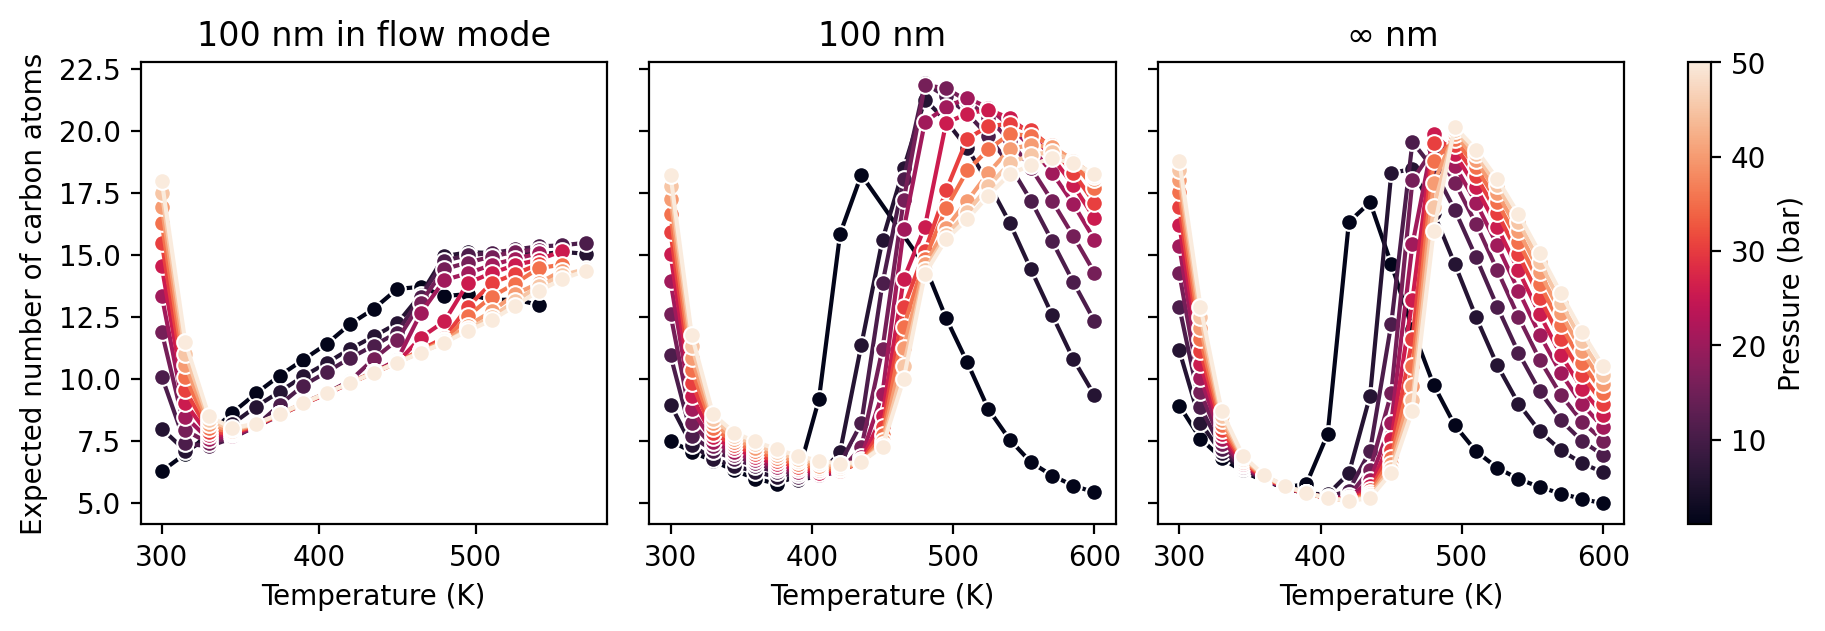

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 3, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')

cmap = "rocket"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (100, True, axs[1]),
    (1000, False, axs[2])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 100')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='expected_n', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('100 nm in flow mode', '100 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_ps.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_ps.svg", bbox_inches="tight")

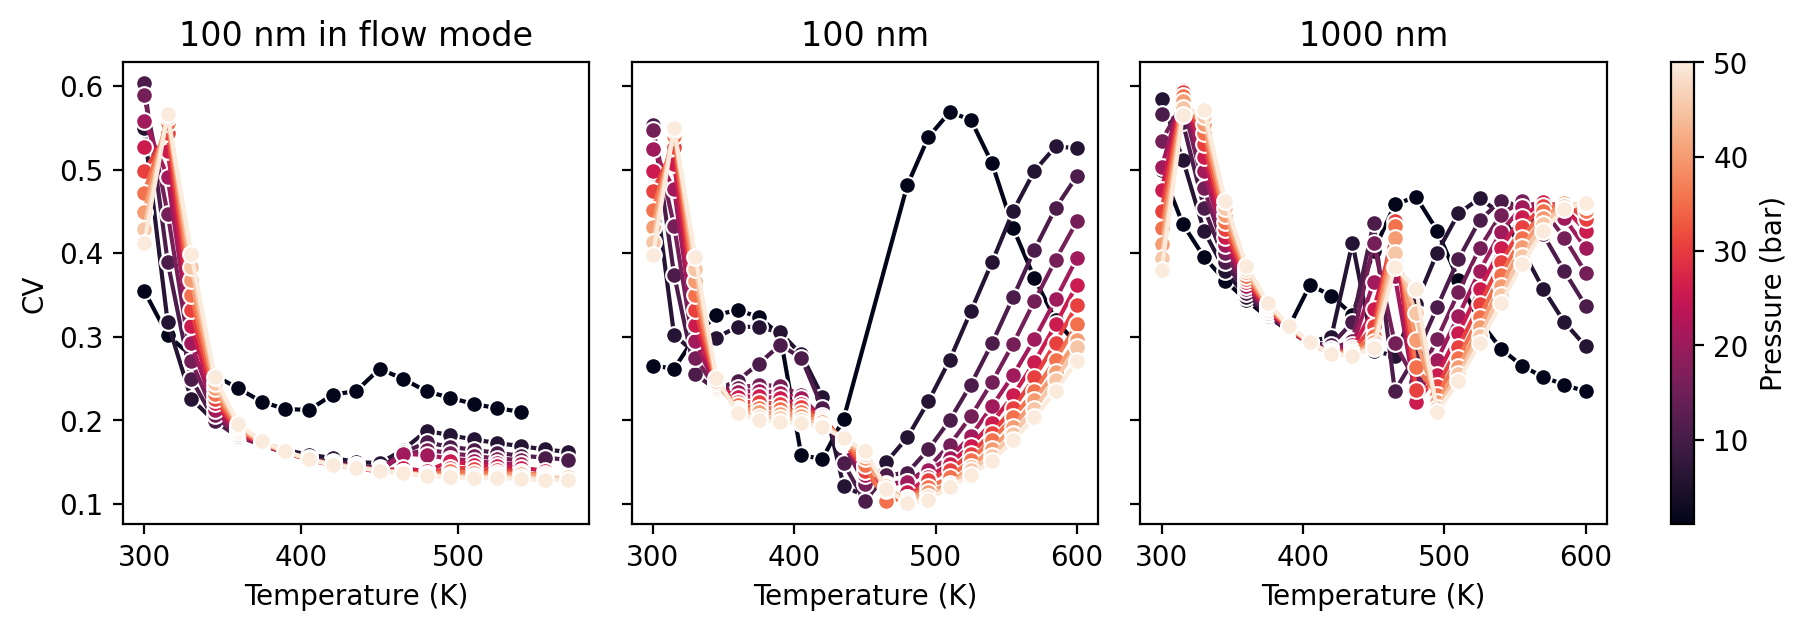

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 3, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')


norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (100, True, axs[1]),
    (1000, False, axs[2])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='coefficient_variance', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 100')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='coefficient_variance', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('100 nm in flow mode', '100 nm', '1000 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('CV')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_CV.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.svg", bbox_inches="tight")

# Kinetic analysis

In [1]:
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
import numpy as np
import joblib
from tqdm import tqdm
import pandas as pd

In [ ]:

c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

N = 8
temperature = 300  # Kelvin
pressure = 2  # bar
steps = 1e4
time = 10
diffusion = False  # Set to False to disable diffusion

df_rates = []
with tqdm(total=101*6) as pbar:
    for temperature in np.linspace(300, 600, 101):
        for pressure in np.linspace(1, 50, 6):

            energy_barriers = EnergyBarriersSimplifyed(
                temperature=temperature,
                pressure=pressure
            )

            reactor = ReactorSimulationChemisorptionSimplified(
                N=N,
                T=temperature,
                pressure=pressure,
                L=1000,
                time_hours=time,
                n_steps=int(steps),
                diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
                ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
                energy_model=energy_barriers,
                initial_concs={'CatC2(C2)': 1e-2, 'C2': 1, 'C2_out': 1},
                include_diffusion=diffusion
            )

            reactor.solver = reactor._build_solver()
            k_ins, k_deins = reactor._reactions[2][1:]
            k_elim, k_deelim = reactor._reactions[-1][1:]
            df_rates.append([k_ins, k_deins, k_elim, k_deelim, pressure, temperature])
            pbar.update(1)

df_rates = pd.DataFrame(df_rates, columns = ['k_ins', 'k_deins', 'k_elim', 'k_deelim', 
                                             'pressure', 'temperature'])
df_rates.to_pickle('files/rates.pkl')

In [9]:
distr = pd.read_pickle('files/distr.pkl')
df_rates = pd.read_pickle('files/rates.pkl')
distr = distr.query('not diffusion and particle_size==1000')

In [28]:
distr['pressure'] = distr['pressure'].round(1)
distr['temperature'] = distr['temperature'].round(1)
df_rates['pressure'] = df_rates['pressure'].round(1)
df_rates['temperature'] = df_rates['temperature'].round(1)

merged = pd.merge(
    distr,
    df_rates,
    on=['pressure', 'temperature'],
    suffixes=('_distr', '_rates')
)
merged = merged.drop(columns=['is_stream', 'diffusion', 'cat_conc', 'expected_n2', 'variance_n', 'std_n', 'particle_size'])
merged['K_growth'] = merged.k_ins/merged.k_deins
merged['K_elimination'] = merged.k_elim/merged.k_deelim
merged.head()

,temperature,pressure,expected_n,coefficient_variance,k_ins,k_deins,k_elim,k_deelim,K_growth,K_elimination
0,300.0,1.0,23.970169,0.025357,0.068697,1.743626e-11,2.143486,394.807435,3.939873e+09,0.005429
1,300.0,10.8,23.969774,0.025521,0.068697,1.614270e-12,0.198446,36.551733,4.255588e+10,0.005429
2,300.0,20.6,23.969373,0.025682,0.068697,8.462878e-13,0.104036,19.162403,8.117411e+10,0.005429
3,300.0,30.4,23.968955,0.025849,0.068697,5.734598e-13,0.070497,12.984787,1.197933e+11,0.005429
4,300.0,40.2,23.968525,0.026018,0.068697,4.336548e-13,0.053310,9.819199,1.584132e+11,0.005429


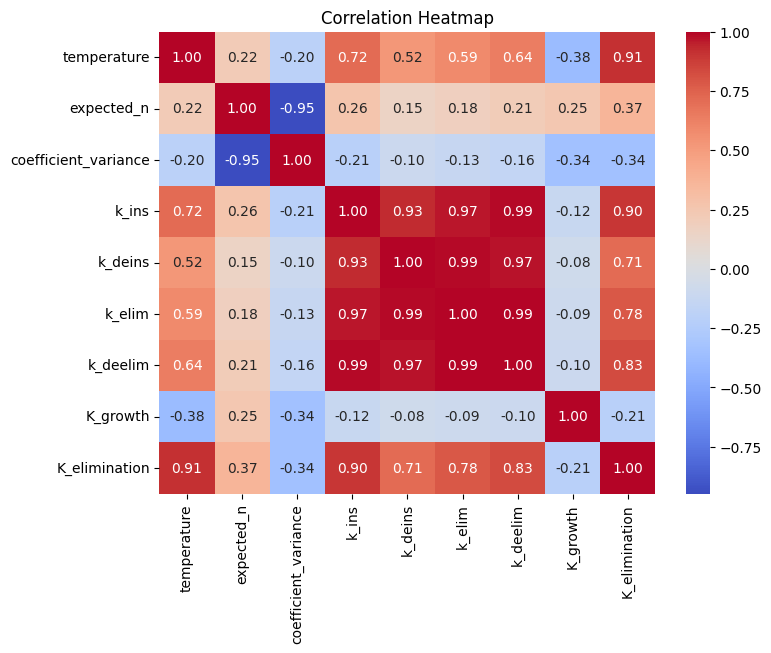

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(merged.query('pressure==50').drop(columns=['pressure']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

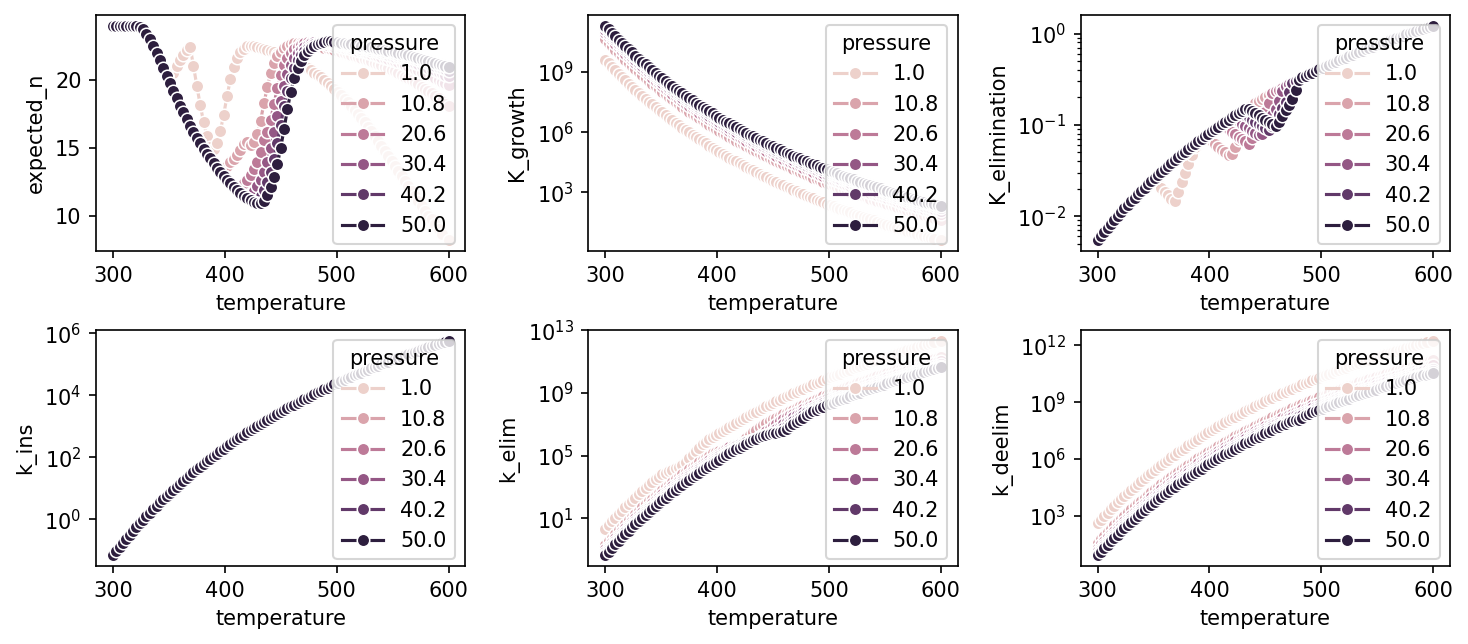

In [64]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5),dpi=150)
sns.lineplot(merged, x='temperature', y='expected_n', hue='pressure', marker='o', ax=axs[0, 0])
sns.lineplot(merged, x='temperature', y='K_growth', hue='pressure', marker='o', ax=axs[0, 1])
sns.lineplot(merged, x='temperature', y='K_elimination', hue='pressure', marker='o', ax=axs[0, 2])

sns.lineplot(merged, x='temperature', y='k_ins', hue='pressure', marker='o', ax=axs[1, 0])
sns.lineplot(merged, x='temperature', y='k_elim', hue='pressure', marker='o', ax=axs[1, 1])
sns.lineplot(merged, x='temperature', y='k_deelim', hue='pressure', marker='o', ax=axs[1, 2])


axs[0, 1].set_yscale('log')
axs[0, 2].set_yscale('log')
axs[1, 0].set_yscale('log')
axs[1, 1].set_yscale('log')
axs[1, 2].set_yscale('log')
for ax in axs.flatten():
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width*0.9, box.height*0.9])

In [60]:
merged.columns

Index(['temperature', 'pressure', 'expected_n', 'coefficient_variance',
       'k_ins', 'k_deins', 'k_elim', 'k_deelim', 'K_growth', 'K_elimination'],
      dtype='object')